# סיווג משלחי יד | מבחן מדען נתונים — V2
### בקרת איכות אוטומטית המופעלת על ידי סוגי השדות ב-Metadata

**מה חדש:** הגיליון `Metadata` מגדיר את חוזה הנתונים. לכל עמודה המנגנון קורא את `פורמט` (`INTEGER`, `TEXT`, `DATE`), מפעיל בדיקות אוטומטיות מתאימות, ובודק קודים ויחסים נוספים **רק כאשר המקור מגדיר אותם**. כל 18 העמודות נבדקות; אין טבלת הגדרות שהועתקה ידנית ואין יצירת ערכי קטגוריות שאינם קיימים במקור.

**מטרת המטלה:** לחזות `SemelMishlachSofi` על נתוני דמה שהוכנו למבחן, ולהציג קוד, תוצאות חיזוי, איכות נתונים, הסבר פתרון ותהליך הטמעה. תוויות הסמלנים אינן אמת-מידה בלתי תלויה, ויש כ-10% שגיאות בתהליך הידני לפי תיאור המטלה. **אין לפרש את המדדים המוצגים כאומדן דיוק של מערכת ייצור.**

**עקרון ההפרדה:** (1) *בדיקת מקור* על העמודות הגולמיות; (2) *מיפוי מדויק של מגבלות המקור*; (3) *מדיניות מידול מקצועית* המוצהרת בנפרד; (4) *אימון ואימות ללא זליגת נתוני בדיקה*.

הנתונים נטענים ישירות [מקובץ Excel ב-GitHub](https://github.com/shulruferor-sudo/Advance-Data-Science/blob/main/Datasets/cbs_occupation_survey_sample/DUMMY_DATASET.xlsx). ניתן לפתוח את [V2 ב-Colab](https://colab.research.google.com/github/shulruferor-sudo/Advance-Data-Science/blob/main/project_notebooks/survey_occupation_classification_v2.ipynb). אין צורך ב-SSH, במפתח גישה, בחיבור Drive או בהטמעת נתוני הסקר בקוד.

**ההגשה הקודמת נשמרת ללא שינוי:** `survey_occupation_classification.ipynb` הוא V1. מחברת זו היא גרסה עצמאית נוספת.

## 1. תלות בסביבה ועקיבות
תא הטעינה משתמש בהורדה אנונימית של קובץ ה-Excel הציבורי מ-GitHub, וכולל SHA-256 של גרסת המקור. לצורך בדיקת הרצה מקומית בלבד אפשר להגדיר `CBS_OCCUPATION_WORKBOOK_PATH` לקובץ זהה בבייטים. ב-Colab אין צורך להגדיר דבר.

In [1]:
from __future__ import annotations
import hashlib
import io
import os
import re
import sys
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
PALETTE = {"blue": "#205F88", "teal": "#317D7B", "gray": "#5B6D7C",
           "pale": "#E1EDF5", "orange": "#B36A24", "edge": "#335879"}
pd.set_option("display.max_rows", 50)
pd.set_option("display.max_colwidth", 65)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

Python 3.13.5 | pandas 2.2.3 | scikit-learn 1.8.0


## 2. טעינת שני הגיליונות לפי המבנה המקורי
קוראים תחילה את ארבע עמודות ההגדרה של `Metadata`, משום שבקובץ המקורי קיימת התפרסות עיצובית של הגיליון אל מעבר לשדות המידע. אחר כך משתמשים בטיפוסי המקור כדי לטעון במפורש את שדות `TEXT` כמחרוזות. קוד `123` נשאר `"123"` ואינו מושלם אוטומטית לארבע ספרות. שורת הסיכום היחידה ללא `ID` אינה משתתף ולכן מוצאת רק *ממערך הניתוח*, בלי לשנות את הקובץ המקורי.

In [2]:
SOURCE_URL = (
    "https://raw.githubusercontent.com/shulruferor-sudo/Advance-Data-Science/"
    "main/Datasets/cbs_occupation_survey_sample/DUMMY_DATASET.xlsx"
)
EXPECTED_SHA256 = "e1e7f391c0675dd14830eaae6b5cd114edc256f18b956bb48a454b0b1209e1ac"
local_test_path = os.environ.get("CBS_OCCUPATION_WORKBOOK_PATH")
if local_test_path:
    excel_bytes = Path(local_test_path).read_bytes()
else:
    req = urllib.request.Request(SOURCE_URL, headers={"User-Agent": "occupation-analysis-v2"})
    with urllib.request.urlopen(req, timeout=60) as response:
        excel_bytes = response.read()
actual_hash = hashlib.sha256(excel_bytes).hexdigest()
assert actual_hash == EXPECTED_SHA256, (
    "Dataset version changed. Inspect Metadata and source rows before reporting results."
)
file = pd.ExcelFile(io.BytesIO(excel_bytes), engine="openpyxl")
assert set(file.sheet_names) == {"Survey Dataset", "Metadata"}
metadata = pd.read_excel(file, sheet_name="Metadata", usecols="A:D", dtype="string")
metadata.columns = metadata.columns.astype(str).str.strip()
meta_fields = ["משתנה", "הסבר", "פורמט", "ערכים אפשריים"]
assert metadata.columns.tolist() == meta_fields
metadata = metadata.loc[metadata["משתנה"].notna(), meta_fields].copy()
for c in ["משתנה", "פורמט"]:
    metadata[c] = metadata[c].str.strip()
assert metadata["משתנה"].is_unique
assert metadata["פורמט"].isin(["INTEGER", "TEXT", "DATE"]).all()
text_columns = metadata.loc[metadata["פורמט"].eq("TEXT"), "משתנה"].tolist()
raw_survey = pd.read_excel(file, sheet_name="Survey Dataset",
                           dtype={field: "string" for field in text_columns})
non_participant = raw_survey.loc[raw_survey["ID"].isna()].copy()
survey = raw_survey.loc[raw_survey["ID"].notna()].copy().reset_index(drop=True)
assert survey.shape == (200, 18)
assert metadata.shape == (18, 4)
assert set(survey.columns) == set(metadata["משתנה"])
assert len(non_participant) == 1
print("Workbook SHA-256:", actual_hash)
print("Survey records:", len(survey), "| Columns:", len(survey.columns),
      "| Metadata definitions:", len(metadata), "| Non-participant summary rows:", len(non_participant))
display(survey[["ID", "EzoAvoda", "SemelMishlachSofi"]].head(5))

Workbook SHA-256: e1e7f391c0675dd14830eaae6b5cd114edc256f18b956bb48a454b0b1209e1ac
Survey records: 200 | Columns: 18 | Metadata definitions: 18 | Non-participant summary rows: 1


,ID,EzoAvoda,SemelMishlachSofi
0,1.0,סגן מנהל אגף,2120
1,2.0,טכנאית רדיותרפיה,3311
2,3.0,נותנת תמיכה ללקוחות שמבקשים עזרה,3512
3,4.0,שומר בבית הספר,5414
4,5.0,מטפל בקשיש,5322


## 3. הפיכת ה-Metadata עצמו לחוזה בדיקות
המנגנון הבא **אינו מעתיק את ההגדרות**: הוא קורא את כל שורות `metadata` ומחלץ רק כללים שהטקסט מספק בפועל.

- `פורמט` קובע אילו בדיקות טיפוס מופעלות בכל עמודה.
- רשימות ממוספרות בגוף `ערכים אפשריים` מפעילות בדיקת תחום עבור הקודים המפורטים בלבד.
- הביטוי "מורכב מ-4 ספרות" מפעיל בדיקת מבנה קוד של ארבעה תווים.
- הכיתוב "משתנה המטרה" מזהה את עמודת היעד.

**הגבלה אפיסטמית:** הטיפוס אינו קובע לבדו היעדר חסרים, מינימום גיל, סדר אורדינלי או הרשאה להשתמש בשדה לחיזוי. מידע כזה דורש הגדרה נפרדת. נתון חסר אינו נחשב אוטומטית לשגיאה, כי המטלה מאפשרת שאלון חלקי.

In [3]:
def parse_enumerated_codes(raw):
    """Codes are extracted only from numbered lines explicitly supplied by Metadata."""
    if pd.isna(raw):
        return {}
    pairs = re.findall(r"(?m)^\s*(\d+)\.\s*(\S[^\n]*?)\s*$", str(raw))
    return {int(number): label.strip() for number, label in pairs}

def code_width_from_description(description):
    if pd.isna(description):
        return None
    match = re.search(r"מורכב\s*מ\s*[-־]?\s*(\d+)\s*ספרות", str(description))
    return int(match.group(1)) if match else None

contracts = metadata.set_index("משתנה", verify_integrity=True)
enumerations = {field: parse_enumerated_codes(contracts.loc[field, "ערכים אפשריים"])
                for field in survey.columns}
widths = {field: code_width_from_description(contracts.loc[field, "הסבר"])
          for field in survey.columns}
identified_targets = metadata.loc[
    metadata["ערכים אפשריים"].fillna("").str.contains("משתנה המטרה", regex=False), "משתנה"
].tolist()
assert identified_targets == ["SemelMishlachSofi"]
TARGET = identified_targets[0]
assert widths["SemelAnafSofi"] == widths[TARGET] == 4
print("Metadata type counts:", contracts["פורמט"].value_counts().to_dict())
print("Enumerations specified in source:", {k:len(v) for k,v in enumerations.items() if v})
print("Four-digit code fields:", [k for k,v in widths.items() if v==4])
for row_start in range(0,len(metadata),4):
    print(f"Metadata definitions {row_start+1}–{min(row_start+4,len(metadata))}")
    display(metadata.iloc[row_start:row_start+4][["משתנה","פורמט","הסבר"]].reset_index(drop=True))

Metadata type counts: {'TEXT': 10, 'INTEGER': 7, 'DATE': 1}
Enumerations specified in source: {'MenahelEtMi': 3, 'MaamadAvoda': 7, 'MakorSachar': 4, 'TeudaGvoha': 9}
Four-digit code fields: ['SemelAnafSofi', 'SemelMishlachSofi']
Metadata definitions 1–4


,משתנה,פורמט,הסבר
0,ID,INTEGER,מספר רץ
1,YeshuvAvoda,TEXT,שם יישוב עבודה
2,ShemAvoda,TEXT,שם מקום העבודה שלך
3,SugAvoda,TEXT,הפעילות העיקרית של מקום העבודה


Metadata definitions 5–8


,משתנה,פורמט,הסבר
0,ShemMachlaka,TEXT,אגף או מחלקה שהנסקר עובד
1,SugMachlaka,TEXT,הפעילות העיקרית של האגף או המחלקה שהנסקר עובד
2,EzoAvoda,TEXT,עבודה שהנסקר עושה במקום עבודה זה
3,TeurPeula,TEXT,הפעולות העיקריות שהנסקר עושה במקום עבודה


Metadata definitions 9–12


,משתנה,פורמט,הסבר
0,TeurTafkid,TEXT,מהו תואר המשרה של הנסקר במקום עבודה זה (במידה ויש)
1,MenahelEtMi,INTEGER,האם הנסקר מנהל או ממונה על עובדים אחרים?
2,MaamadAvoda,INTEGER,מעמד הנסקר במקום עבודה זה
3,MakorSachar,INTEGER,מקור השכר של הנסקר (השדה מלא רק במידה והנסקר שכיר או חבר קואו...


Metadata definitions 13–16


,משתנה,פורמט,הסבר
0,TeudaGvoha,INTEGER,התעודה או התואר הגבוה ביותר של הנסקר
1,shnotlimud,INTEGER,שנות הלימוד של הנסקר
2,Gil,INTEGER,גיל הנסקר
3,SemelAnafSofi,TEXT,סמל ענף כלכלי של מקום העבודה - מורכב מ-4 ספרות לפי תקן בינלאומי


Metadata definitions 17–18


,משתנה,פורמט,הסבר
0,TarichHathala,DATE,תאריך התחלת התפקיד
1,SemelMishlachSofi,TEXT,סמל משלח יד - מורכב מ-4 ספרות לפי תקן בינלאומי


## 4. מנוע הבדיקות: טיפוס השדה מפעיל את הבדיקות
`validate_type()` הוא פונקציית ניתוב לפי `פורמט`, שאינה מכילה רשימה ידנית של 18 תיאורי עמודות. כל תוצאה היא מסכת שורות המשויכת לשדה ולכלל המקור. הודעות חריגה אינן מוחקות ערכים ואינן מבצעות המרות שקטות.

**`INTEGER`:** זיהוי ערכים שאינם מספרים, שברים שאינם מספרים שלמים, והפרת רשימה ממוספרת אם קיימת במטא-דאטה. **`TEXT`:** טיפול באחסון כמחרוזת ובדיקת רוחב לקודים רק כאשר הוא מוצהר. **`DATE`:** זיהוי תאריכים שאי אפשר לפענח. לכל טיפוס נרשמים חסרים, שכיחויות ושונות כמדדי תיאור, ללא הנחת חובה למלא.

In [4]:
def occupied(series):
    return series.notna() & series.astype("string").str.strip().fillna("").ne("")

def validate_type(frame, field):
    """Return row-level masks. Source values are never changed."""
    kind = str(contracts.loc[field, "פורמט"])
    series = frame[field]
    nonempty = occupied(series)
    flags = {}
    if kind == "INTEGER":
        numeric = pd.to_numeric(series, errors="coerce")
        flags["non_numeric"] = nonempty & numeric.isna()
        flags["non_integral"] = (numeric.notna() & numeric.mod(1).ne(0)).fillna(False)
        if enumerations[field]:
            flags["outside_enumeration"] = (
                numeric.notna() & ~numeric.isin(enumerations[field])
            ).fillna(False)
    elif kind == "TEXT":
        if widths[field] is not None:
            text = series.astype("string").str.strip()
            pattern = rf"[0-9Xx]{{{widths[field]}}}"
            flags["code_shape_mismatch"] = (
                nonempty & ~text.str.fullmatch(pattern, na=False)
            ).fillna(False)
            flags["partial_X_code"] = (
                nonempty & text.str.fullmatch(pattern, na=False)
                & text.str.contains("X",case=False,regex=False,na=False)
            ).fillna(False)
    elif kind == "DATE":
        parsed = pd.to_datetime(series,errors="coerce",format="mixed")
        flags["unparseable_date"] = nonempty & parsed.isna()
    else:
        raise ValueError(f"Metadata type {kind!r} is unsupported; no silent fallback")
    return {rule: mask.astype(bool) for rule,mask in flags.items()}

source_issues = []
summary_rows = []
checklist_rows = []
for field in survey.columns:
    flags = validate_type(survey, field)
    is_present = occupied(survey[field])
    checks = ["presence", "type:"+contracts.loc[field,"פורמט"]]
    if enumerations[field]: checks.append("declared_domain")
    if widths[field]: checks.append("declared_code_width")
    for rule, mask in flags.items():
        if not mask.any() or rule=="partial_X_code": continue  # A partial code is a review status, not a type-contract violation.
        for idx in survey.index[mask]:
            source_issues.append({"ID": survey.loc[idx,"ID"], "field":field,
                                  "rule":rule, "original":str(survey.loc[idx,field]),
                                  "provenance":"Metadata: "+str(contracts.loc[field,"פורמט"])})
    populated = survey.loc[is_present,field].astype("string").str.strip()
    summary_rows.append({"field":field, "type":str(contracts.loc[field,"פורמט"]),
                         "missing":int((~is_present).sum()),
                         "missing_pct":round(float((~is_present).mean()*100),1),
                         "distinct_nonmissing":int(populated.nunique()),
                         "checks":", ".join(checks),
                         "violations":sum(int(mask.sum()) for rule,mask in flags.items()
                                          if rule!="partial_X_code"),
                         "X_partial":int(flags.get("partial_X_code",pd.Series(False,index=survey.index)).sum())})
    checklist_rows.append({"field":field,
        "presence":True,
        "integer":contracts.loc[field,"פורמט"]=="INTEGER",
        "text":contracts.loc[field,"פורמט"]=="TEXT",
        "date":contracts.loc[field,"פורמט"]=="DATE",
        "enumeration":bool(enumerations[field]),
        "code_width":widths[field] is not None})
summary=pd.DataFrame(summary_rows)
issues=pd.DataFrame(source_issues,columns=["ID","field","rule","original","provenance"])
checklist=pd.DataFrame(checklist_rows).set_index("field")
assert len(summary)==18 and checklist.shape==(18,6)
for start in range(0,len(summary),6):
    display(summary.iloc[start:start+6][["field","type","missing","missing_pct","violations","X_partial"]])
print("Source violations (excluding valid partial X labels):",len(issues))
print("Validation issues by rule:")
display(issues.groupby(["rule","field"]).size().rename("records").reset_index() if len(issues)
        else pd.DataFrame({"status":["No type-validation violations"]}))

,field,type,missing,missing_pct,violations,X_partial
0,ID,INTEGER,0,0.0,0,0
1,YeshuvAvoda,TEXT,0,0.0,0,0
2,ShemAvoda,TEXT,0,0.0,0,0
3,SugAvoda,TEXT,25,12.5,0,0
4,ShemMachlaka,TEXT,64,32.0,0,0
5,SugMachlaka,TEXT,134,67.0,0,0


,field,type,missing,missing_pct,violations,X_partial
6,EzoAvoda,TEXT,7,3.5,0,0
7,TeurPeula,TEXT,136,68.0,0,0
8,TeurTafkid,TEXT,172,86.0,0,0
9,MenahelEtMi,INTEGER,168,84.0,0,0
10,MaamadAvoda,INTEGER,2,1.0,0,0
11,MakorSachar,INTEGER,14,7.0,0,0


,field,type,missing,missing_pct,violations,X_partial
12,TeudaGvoha,INTEGER,2,1.0,0,0
13,shnotlimud,INTEGER,2,1.0,0,0
14,Gil,INTEGER,2,1.0,0,0
15,TarichHathala,DATE,0,0.0,0,0
16,SemelAnafSofi,TEXT,0,0.0,5,9
17,SemelMishlachSofi,TEXT,0,0.0,0,9


Source violations (excluding valid partial X labels): 5
Validation issues by rule:


,rule,field,records
0,code_shape_mismatch,SemelAnafSofi,5


## 5. בדיקות יחידה למנגנון — הוכחה שהכללים אכן מופעלים
לפני שימוש עסקי, משנים **עותק בדיקה זמני בלבד** ומוכיחים שהמנגנון מגלה קלט לא תקין. הבדיקות בוחנות את הטיפוס, תחום הקודים והמבנה המוגדר במקור. שום שינוי אינו נשמר בקובץ הסקר.

In [5]:
def assert_detected(field, invalid, expected_rule):
    sample = survey[[field]].astype({field: "object"}).copy()
    sample.loc[0,field] = invalid
    observed = validate_type(sample,field)
    assert expected_rule in observed, (field,expected_rule)
    assert observed[expected_rule].iloc[0], (field,invalid,expected_rule)

assert_detected("shnotlimud", "not-an-integer", "non_numeric")
assert_detected("Gil", 31.5, "non_integral")
assert_detected("MaamadAvoda", 99, "outside_enumeration")
assert_detected("TarichHathala", "not-a-date", "unparseable_date")
assert_detected("SemelAnafSofi", "12", "code_shape_mismatch")
assert_detected("SemelMishlachSofi", "1X3X", "partial_X_code")
assert sum(int(m.sum()) for rule,m in validate_type(survey,"EzoAvoda").items())==0
print("6 mutated-input tests and 1 source-text control: PASSED")

6 mutated-input tests and 1 source-text control: PASSED


## 6. הפעלת בדיקות רוחב על כל השדות — תצוגה גרפית
מטריצת הפעלה מסבירה בדיוק מה מופעל אוטומטית עבור כל שדה. התרשימים נגזרים מן הטיפוסים והקודים שנמצאו ב-Metadata המקורי; הם אינם נתונים מיוצרים ואינם תחומי ערכים משוערים.

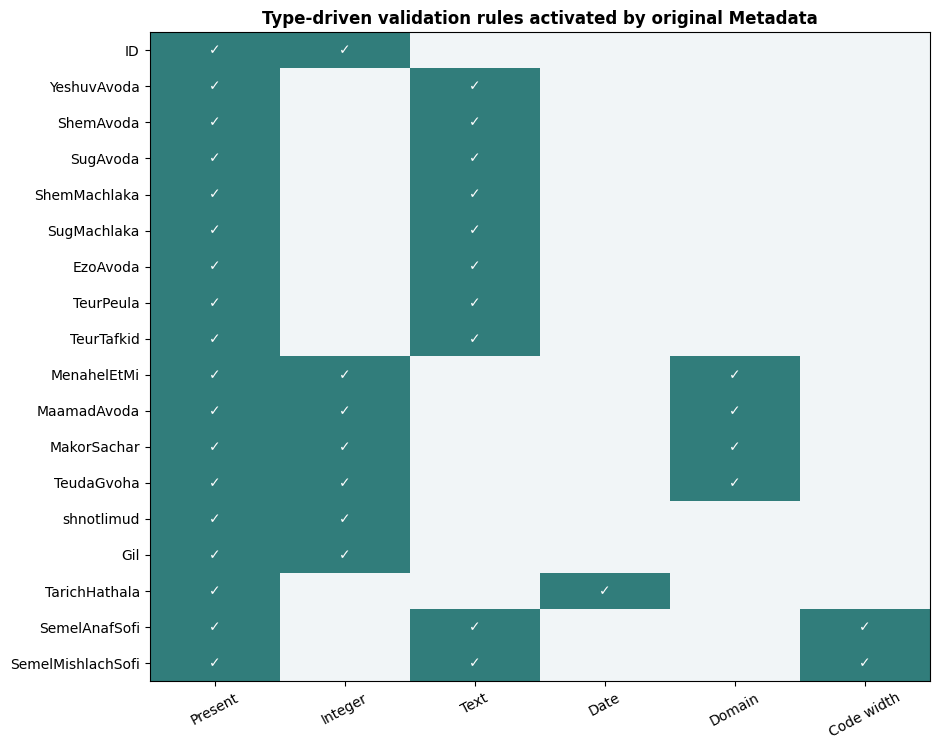

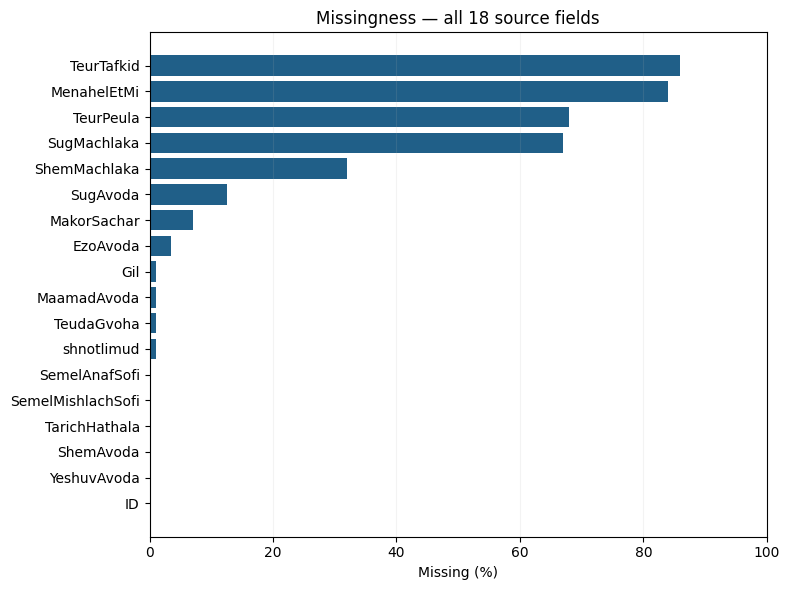

In [6]:
fig, ax = plt.subplots(figsize=(9.5,7.6))
ax.imshow(checklist.astype(int).values, aspect="auto",
          cmap=ListedColormap(["#F1F5F7",PALETTE["teal"]]), vmin=0,vmax=1)
ax.set_yticks(range(len(checklist.index)),labels=checklist.index)
ax.set_xticks(range(len(checklist.columns)),labels=["Present","Integer","Text","Date","Domain","Code width"])
ax.tick_params(axis='x', labelrotation=28)
for y in range(len(checklist.index)):
    for x in range(len(checklist.columns)):
        if checklist.iat[y,x]: ax.text(x,y,"✓",va="center",ha="center",color="white",fontsize=10)
ax.set_title("Type-driven validation rules activated by original Metadata",fontweight="bold")
fig.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8,6.0))
ordered=summary.sort_values("missing_pct")
ax.barh(ordered["field"],ordered["missing_pct"],color=PALETTE["blue"])
ax.set(xlabel="Missing (%)",title="Missingness — all 18 source fields",xlim=(0,100))
ax.grid(axis="x",alpha=.15)
fig.tight_layout();plt.show()

## 7. תרשים מותאם-טיפוס לכל אחד מ-18 השדות
פונקציית השרטוט עצמה קוראת את הטיפוס והערכים מהמקור. `INTEGER` עם ערכים מקודדים מוצג כקטגוריות, `INTEGER` חופשי כהיסטוגרמה, `DATE` לפי שנה, `TEXT` לפי שכיחויות. אין להמיר את קודי ההשכלה לסולם מספרי רק משום שפורמט השדה הוא `INTEGER`. תוויות עבריות ארוכות מוצגות בטבלת הסבר נפרדת כדי למנוע טקסט קטוע ב-Colab בנייד.

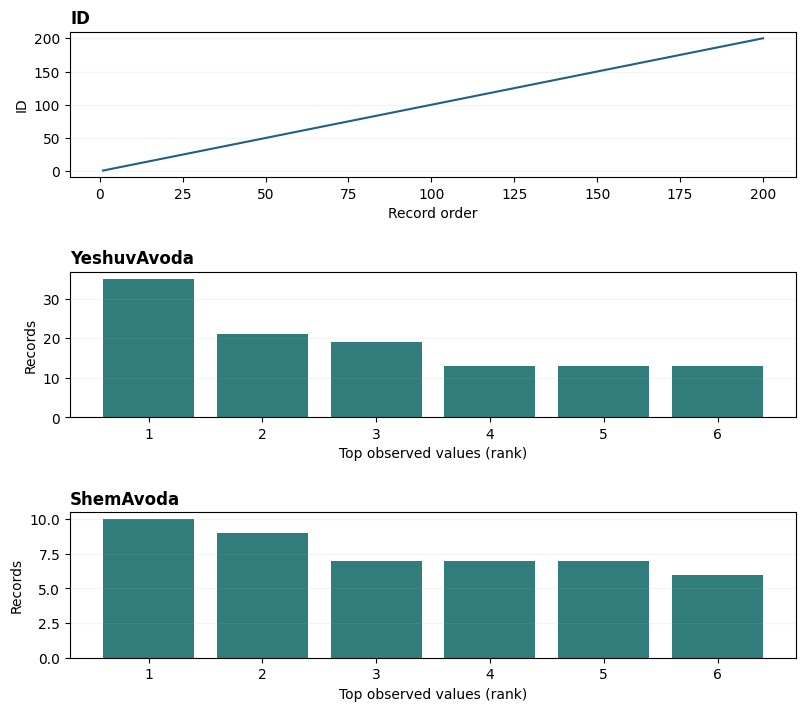

YeshuvAvoda: top observed source text: תל אביב (35) | ירושלים (21) | חיפה (19)
ShemAvoda: top observed source text: מסעדה (10) | משרד החינוך (9) | בנק לאומי (7)


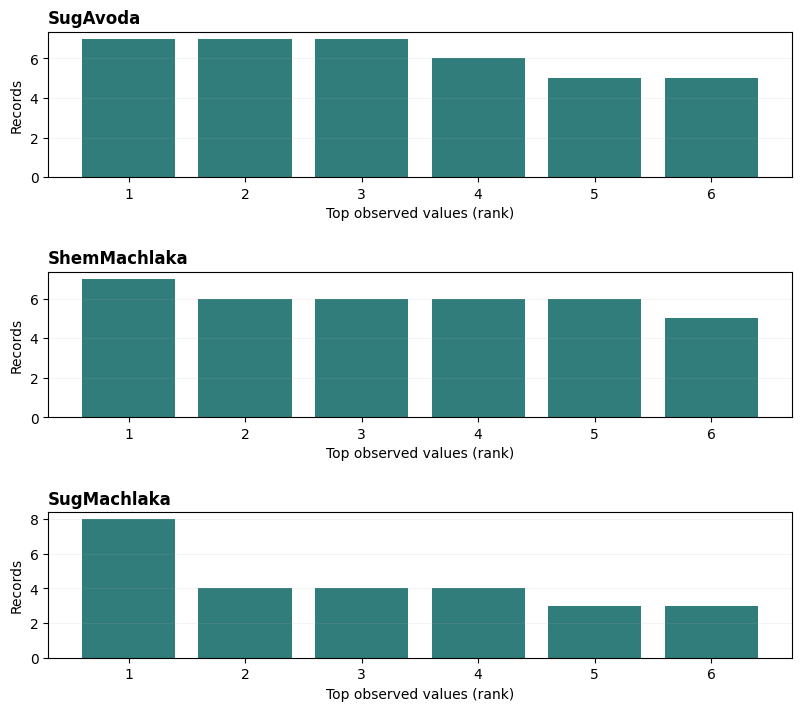

SugAvoda: top observed source text: בית ספר יסודי (7) | מסעדה (7) | חנות למכירת בגדים (7)
ShemMachlaka: top observed source text: שמירה (7) | תמיכה בלקוחות (6) | קוסמטיקה וטיפוח (6)
SugMachlaka: top observed source text: כנ"ל (8) | טיפול בחולי סרטן (4) | טיפול באנשים עם בעיות (4)


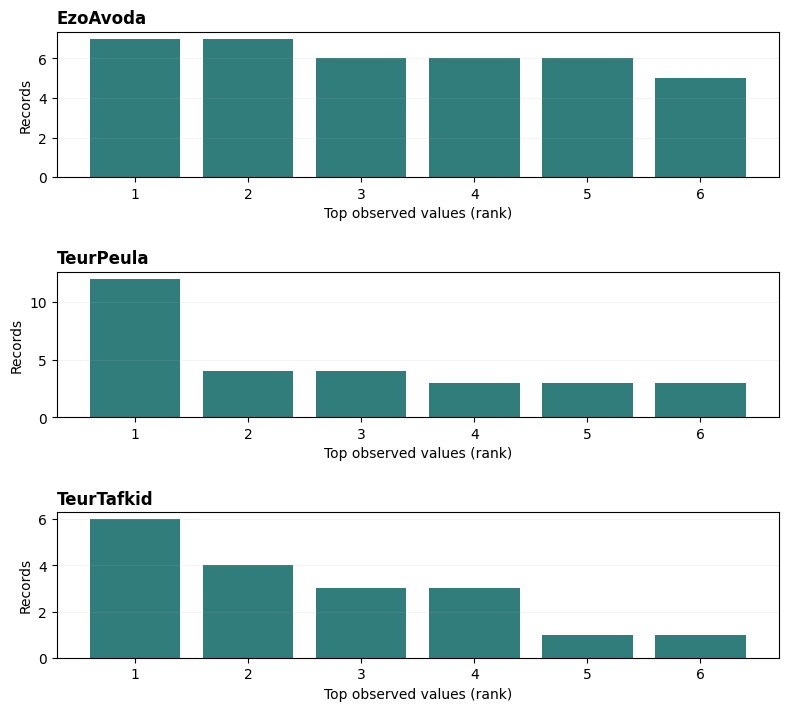

EzoAvoda: top observed source text: שומר בבית הספר (7) | טבח (7) | מנקה בית ספר אחרי הלימודים (6)
TeurPeula: top observed source text: כנ"ל (12) | מפקח על תהליך ייצור צ'יפים (4) | מסבירה לאנשים לגבי מוצרים של חברת LOREAL (4)
TeurTafkid: top observed source text: כלכלן (6) | כנ"ל (4) | סגן מנהל אגף (3)


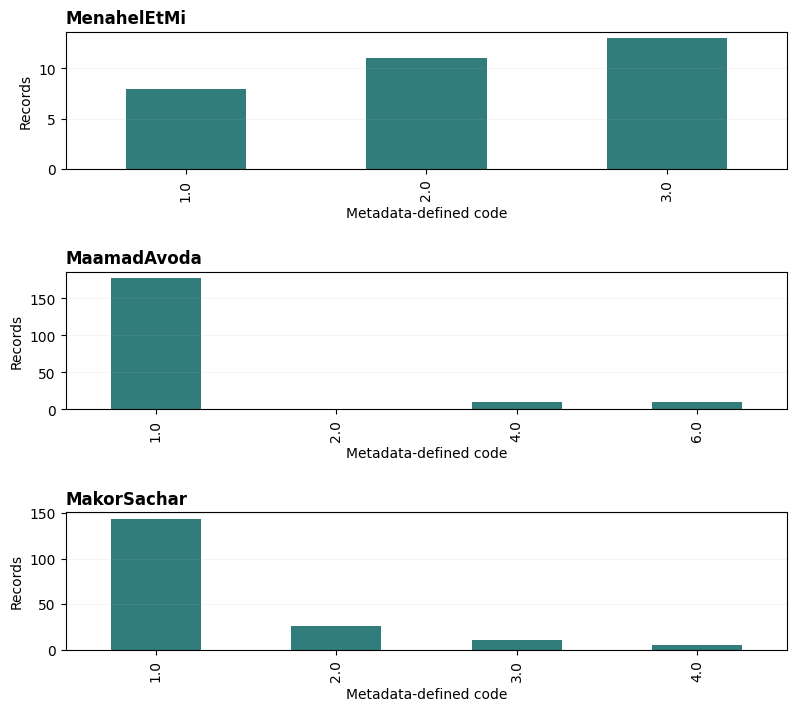

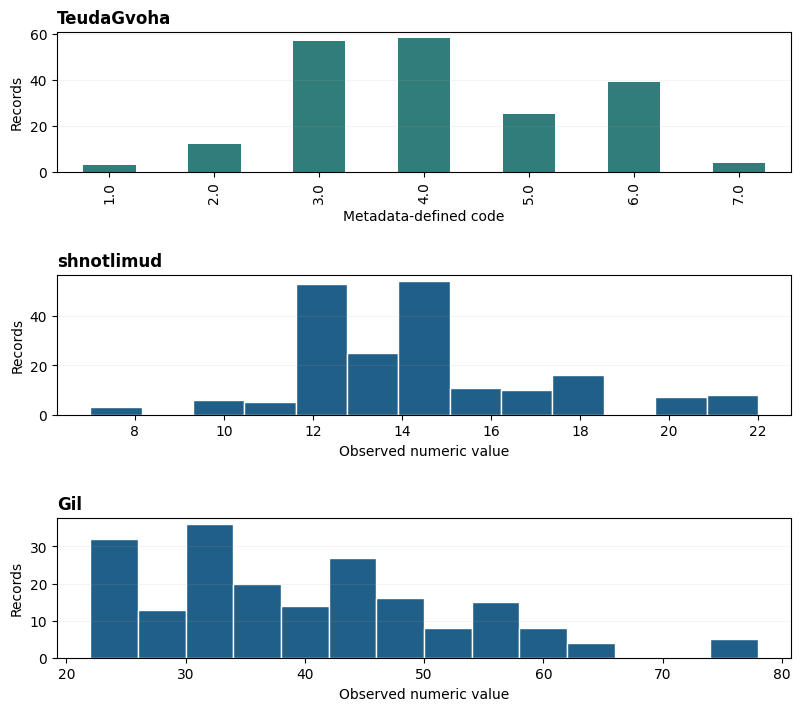

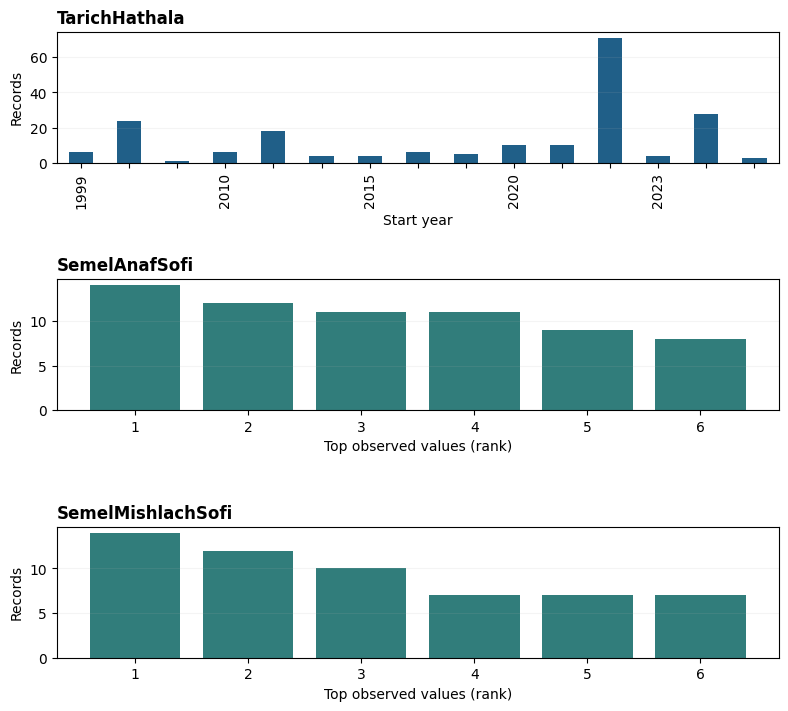

SemelAnafSofi: top observed source text: 5610 (14) | 6201 (12) | 8411 (11)
SemelMishlachSofi: top observed source text: 5223 (14) | 9112 (12) | 2512 (10)


In [7]:
def plot_from_type(field,ax):
    kind=contracts.loc[field,"פורמט"]
    s=survey[field]
    if kind=="DATE":
        yearly=pd.to_datetime(s,errors="coerce",format="mixed").dt.year.value_counts().sort_index()
        yearly.plot.bar(ax=ax,color=PALETTE["blue"])
        ax.set(xlabel="Start year",ylabel="Records")
        for n,item in enumerate(ax.get_xticklabels()):
            if n%3: item.set_visible(False)
    elif kind=="INTEGER" and enumerations[field]:
        counts=pd.to_numeric(s,errors="coerce").value_counts().sort_index()
        counts.plot.bar(ax=ax,color=PALETTE["teal"])
        ax.set(xlabel="Metadata-defined code",ylabel="Records")
    elif kind=="INTEGER" and field!="ID":
        nums=pd.to_numeric(s,errors="coerce").dropna()
        ax.hist(nums,bins=min(14,max(2,nums.nunique())),color=PALETTE["blue"],edgecolor="white")
        ax.set(xlabel="Observed numeric value",ylabel="Records")
    elif field=="ID":
        ax.plot(range(1,len(s)+1),pd.to_numeric(s),color=PALETTE["blue"])
        ax.set(xlabel="Record order",ylabel="ID")
    else:
        cleaned=s.astype("string").str.strip().replace("",pd.NA)
        counts=cleaned.value_counts().head(6)
        ax.bar(range(1,len(counts)+1),counts.values,color=PALETTE["teal"])
        ax.set_xticks(range(1,len(counts)+1))
        ax.set(xlabel="Top observed values (rank)",ylabel="Records")
    ax.set_title(field,loc="left",fontweight="bold",fontsize=12)
    ax.grid(axis="y",alpha=.13)

for start in range(0,len(survey.columns),3):
    fields=list(survey.columns[start:start+3])
    fig,axes=plt.subplots(len(fields),1,figsize=(8.4,7.5))
    for field,ax in zip(fields,np.atleast_1d(axes)):
        plot_from_type(field,ax)
    fig.tight_layout(pad=2.1)
    plt.show()
    for field in fields:
        if contracts.loc[field,"פורמט"]=="TEXT" and field!="ID":
            s=survey[field].astype("string").str.strip().replace("",pd.NA)
            observed=s.value_counts().head(3)
            print(f"{field}: top observed source text:",
                  " | ".join(f"{str(value)[:65]} ({count})" for value,count in observed.items()))

## 8. הפעלת כללים המצריכים משמעות של שדות — בנפרד מבדיקות טיפוס
בדיקות טיפוס לבדן אינן יכולות לקבוע אם שדה רלוונטי רק למעמד תעסוקה מסוים. בגיליון `Metadata` נכתב במפורש כי `MakorSachar` מלא רק עבור שכיר או חבר קואופרטיב, כפי שמוגדר ב-`MaamadAvoda`. הקודים המותרים נגזרים מהטקסט של **הערכים הממוספרים במקור**, ולא ממספרים שהוגדרו מראש בקוד.

הטענה "מלא רק כאשר ..." היא **תנאי הכרחי**, לא הוראה למלא תמיד כאשר התנאי מתקיים. לכן חוסר בשדה אצל שכיר אינו מסווג אוטומטית כהפרת חוזה. קוד סופי הכולל `X` מוגדר לפי מסמך המטלה כקוד חלקי, ולא מניחים שאפשר לשחזר אותו אוטומטית.

Applicable statuses (read from Metadata labels): {1, 5}
Salary-source conflicts: 9
Salary source with unknown status: 0
IDs of rule conflicts: [34, 49, 112, 140, 166, 176, 187, 190, 198]
Four-character target labels: 191 | target labels containing X: 9
Industry code-shape mismatches: 5
Industry X partial codes: 9


,field,rule,records
0,MakorSachar,salary_status_applicability,9
1,SemelAnafSofi,code_shape_mismatch,5


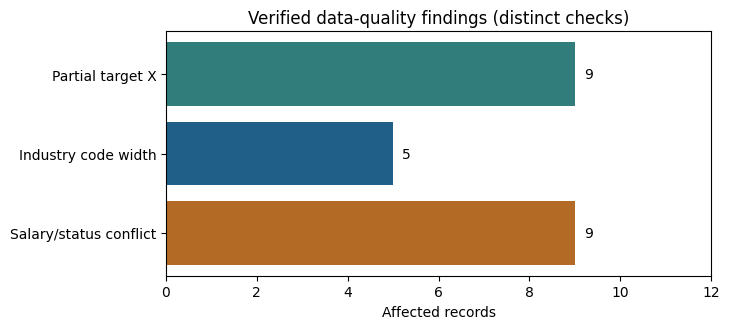

In [8]:
salary_field = metadata.loc[
    metadata["הסבר"].fillna("").str.contains("רק במידה",regex=False),"משתנה"
].tolist()
assert salary_field == ["MakorSachar"]
assert "MaamadAvoda" in str(contracts.loc["MakorSachar","הסבר"])
status_codes = enumerations["MaamadAvoda"]
salary_applicable_codes = {number for number,meaning in status_codes.items()
                           if "שכיר" in meaning or "חבר קואופרטיב" in meaning}
assert salary_applicable_codes == {1,5}, "Check the source's employment-status semantics"
status = pd.to_numeric(survey["MaamadAvoda"],errors="coerce")
salary_present = occupied(survey["MakorSachar"])
not_applicable = status.notna() & ~status.isin(salary_applicable_codes)
invalid_salary_context = not_applicable & salary_present
unknown_salary_context = status.isna() & salary_present
print("Applicable statuses (read from Metadata labels):",salary_applicable_codes)
print("Salary-source conflicts:",int(invalid_salary_context.sum()))
print("Salary source with unknown status:",int(unknown_salary_context.sum()))
print("IDs of rule conflicts:",survey.loc[invalid_salary_context,"ID"].astype(int).tolist())
assert invalid_salary_context.sum()==9
assert not unknown_salary_context.any()

industry_flags=validate_type(survey,"SemelAnafSofi")
target_flags=validate_type(survey,TARGET)
complete_mask = occupied(survey[TARGET]) & ~target_flags["partial_X_code"] & ~target_flags["code_shape_mismatch"]
partial_mask = target_flags["partial_X_code"]
assert int(complete_mask.sum())==191 and int(partial_mask.sum())==9
print("Four-character target labels:",int(complete_mask.sum()),
      "| target labels containing X:",int(partial_mask.sum()))
print("Industry code-shape mismatches:",int(industry_flags["code_shape_mismatch"].sum()))
print("Industry X partial codes:",int(industry_flags["partial_X_code"].sum()))

cross_issues=pd.DataFrame({"ID":survey.loc[invalid_salary_context,"ID"].astype(int),
                           "field":"MakorSachar","rule":"salary_status_applicability",
                           "source":"Metadata description and MaamadAvoda enumerated labels"})
issue_totals=(pd.concat([issues[["ID","field","rule"]],cross_issues[["ID","field","rule"]]],
                       ignore_index=True)
                .groupby(["field","rule"]).size().rename("records").reset_index())
display(issue_totals)

fig,ax=plt.subplots(figsize=(7.4,3.4))
keys=["Partial target X","Industry code width","Salary/status conflict"]
vals=[int(partial_mask.sum()),int(industry_flags["code_shape_mismatch"].sum()),int(invalid_salary_context.sum())]
ax.barh(keys[::-1],vals[::-1],color=[PALETTE["orange"],PALETTE["blue"],PALETTE["teal"]])
ax.set(xlabel="Affected records",title="Verified data-quality findings (distinct checks)")
for i,value in enumerate(vals[::-1]):ax.text(value+.2,i,str(value),va="center")
ax.set_xlim(0,max(vals)+3)
fig.tight_layout();plt.show()

## 9. כפילויות ותוויות סותרות
המסמך מתאר שידורים חוזרים. אולם `ID` הוא "מספר רץ" לפי Metadata ואינו מזהה משתתף יציב, ואין תאריך שידור. לפיכך אי אפשר להסיק שמספר שורות שייכות לאותו אדם. כתחליף מוגבל נבנית חתימה של שבעה שדות תיאור, המשמשת רק לבדיקת דמיון ולחלוקת אימון/בדיקה מופרדת קבוצות. כל שינוי בתיאורי הסקר עלול ליצור קבוצה חדשה גם אם מדובר באותו משתתף.

In [9]:
assert pd.to_numeric(survey["ID"],errors="coerce").is_unique
GROUP_FIELDS=["ShemAvoda","SugAvoda","ShemMachlaka","SugMachlaka",
              "EzoAvoda","TeurPeula","TeurTafkid"]
def normal_signature(x):
    if pd.isna(x): return ""
    return " ".join(re.sub(r"[^\w\u0590-\u05ff]+"," ",str(x).lower()).split())
groups=survey[GROUP_FIELDS].apply(
    lambda row:"|".join(normal_signature(row[k]) for k in GROUP_FIELDS),axis=1)
clusters=(survey.assign(group_signature=groups)
          .groupby("group_signature",dropna=False)
          .agg(records=("ID","size"),distinct_target_labels=(TARGET,"nunique")))
print("Description groups:",len(clusters),
      "| groups repeated:",int(clusters.records.gt(1).sum()),
      "| conflicting-label groups:",int(clusters.distinct_target_labels.gt(1).sum()))
conflict_keys=set(clusters.index[clusters.distinct_target_labels.gt(1)])
display(survey.loc[groups.isin(conflict_keys),["ID","ShemAvoda","EzoAvoda",TARGET]])

Description groups: 137 | groups repeated: 40 | conflicting-label groups: 1


,ID,ShemAvoda,EzoAvoda,SemelMishlachSofi
1,2.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3311
32,33.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3211
64,65.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3211
95,96.0,בית חולים הדסה עין כרם,טכנאית רדיותרפיה,3211


## 10. אישור החלטות על תכונות — מבוסס סוג, אך אינו מוכתב רק ממנו
**הפרדת תחומי אחריות:** `TEXT` מפעיל בדיקות טקסט אבל אינו אומר שכל טקסט צריך להיכלל במודל; `INTEGER` עם ערכים ממוספרים הוא *משתנה קטגוריאלי* ולא ערך רציף. זמינות השדה בזמן אמת והסיכון לזליגה נקבעים לפי משמעותו ותהליך הסימול.

המודל משתמש בשישה תיאורי עבודה, בארבעה שדות עם קודים ממוספרים ובשנות לימוד. `ID` הוא זיהוי בלבד; שם המעסיק והיישוב נשארים לצורכי ביקורת וקיבוץ; גיל ותאריך התחלה מוצגים אך אינם תכונות במודל הבסיסי; `SemelAnafSofi` מוחרג כי זמינות הסמל הענפי הסופי לפני סיווג משלח היד אינה מוכחת; היעד לעולם אינו נכלל בתכונות. זו **מדיניות אנליטית מפורשת**, לא תוכן שהמצאנו ל-Metadata.

In [10]:
APPROVED_TEXT=["SugAvoda","ShemMachlaka","SugMachlaka",
               "EzoAvoda","TeurPeula","TeurTafkid"]
APPROVED_CATEGORICAL=["MenahelEtMi","MaamadAvoda","MakorSachar","TeudaGvoha"]
APPROVED_NUMERIC=["shnotlimud"]
FEATURES=APPROVED_TEXT+APPROVED_CATEGORICAL+APPROVED_NUMERIC
EXCLUDED=[name for name in survey.columns if name not in FEATURES]
assert len(FEATURES)==11 and len(EXCLUDED)==7
assert all(contracts.loc[name,"פורמט"]=="TEXT" and not widths[name] for name in APPROVED_TEXT)
assert all(contracts.loc[name,"פורמט"]=="INTEGER" and bool(enumerations[name])
           for name in APPROVED_CATEGORICAL)
assert all(contracts.loc[name,"פורמט"]=="INTEGER" and not enumerations[name]
           for name in APPROVED_NUMERIC)
assert TARGET in EXCLUDED and "SemelAnafSofi" in EXCLUDED

for name in survey.columns:
    role=("TEXT_TFIDF" if name in APPROVED_TEXT else
          "NOMINAL_ONE_HOT" if name in APPROVED_CATEGORICAL else
          "NUMERIC_IMPUTE_SCALE" if name in APPROVED_NUMERIC else
          "TARGET_NOT_FEATURE" if name==TARGET else
          "AUDIT_AND_GROUP_ONLY" if name=="ShemAvoda" else
          "AUDIT_EXCLUDED")
    r=summary.loc[summary.field.eq(name)].iloc[0]
    print(f"{name:20} Metadata={r['type']:7} Role={role:22} "
          f"Missing={r['missing']:3} Type issues={r['violations']:2}")

ID                   Metadata=INTEGER Role=AUDIT_EXCLUDED         Missing=  0 Type issues= 0
YeshuvAvoda          Metadata=TEXT    Role=AUDIT_EXCLUDED         Missing=  0 Type issues= 0
ShemAvoda            Metadata=TEXT    Role=AUDIT_AND_GROUP_ONLY   Missing=  0 Type issues= 0
SugAvoda             Metadata=TEXT    Role=TEXT_TFIDF             Missing= 25 Type issues= 0
ShemMachlaka         Metadata=TEXT    Role=TEXT_TFIDF             Missing= 64 Type issues= 0
SugMachlaka          Metadata=TEXT    Role=TEXT_TFIDF             Missing=134 Type issues= 0
EzoAvoda             Metadata=TEXT    Role=TEXT_TFIDF             Missing=  7 Type issues= 0
TeurPeula            Metadata=TEXT    Role=TEXT_TFIDF             Missing=136 Type issues= 0
TeurTafkid           Metadata=TEXT    Role=TEXT_TFIDF             Missing=172 Type issues= 0
MenahelEtMi          Metadata=INTEGER Role=NOMINAL_ONE_HOT        Missing=168 Type issues= 0
MaamadAvoda          Metadata=INTEGER Role=NOMINAL_ONE_HOT        Miss

## 11. אימון ב-scikit-learn Pipeline — למידה על אימון בלבד
רק תהליכים שאינם "לומדים" פרמטרים מופעלים לפני הפיצול: ניקוי רווחים, אי-פירוש ביטויים סתמיים, סימון שדה `MakorSachar` כ"לא ישים" עבור מצב לא מתאים. `TF-IDF`, `OneHotEncoder`, חציון השלמה, תקנון ומודל נלמדים *רק על קבוצת האימון* בתוך `Pipeline`. הבחירה במודל ליניארי רגולריזטורי היא הדגמת תהליך הניתנת להסבר, ולא טענה שהמודל מיטבי.

**קודי X:** תשע הרשומות עם סימול חלקי מוחרגות מאימון מפוקח ומהערכה, ונשמרות לצורך הצעות לסמלן בלבד.

In [11]:
NO_SIGNAL_TEXT={"כנ\"ל","כנ״ל","חסוי","לא יכול לפרט","0"}

def model_features(frame):
    result=pd.DataFrame(index=frame.index)
    for field in APPROVED_TEXT:
        x=frame[field].astype("string").fillna("")
        x=x.str.replace(r"\s+"," ",regex=True).str.strip()
        result[field]=x.mask(x.isin(NO_SIGNAL_TEXT),"").astype(str)
    for field in APPROVED_CATEGORICAL:
        x=pd.to_numeric(frame[field],errors="coerce").astype("Int64")
        result[field]=x.astype("string").fillna("MISSING").astype(str)
    applicable=pd.to_numeric(frame["MaamadAvoda"],errors="coerce").isin(salary_applicable_codes)
    is_unknown=frame["MaamadAvoda"].isna()
    result.loc[~applicable & ~is_unknown,"MakorSachar"]="NOT_APPLICABLE"
    result.loc[is_unknown,"MakorSachar"]="APPLICABILITY_UNKNOWN"
    for field in APPROVED_NUMERIC:
        result[field]=pd.to_numeric(frame[field],errors="coerce")
    return result[FEATURES]

text_pipelines=[(f"char_{field}",
                  TfidfVectorizer(analyzer="char",ngram_range=(2,4),
                                  max_features=4000,sublinear_tf=True),field)
                for field in APPROVED_TEXT]
transformer=ColumnTransformer(
    transformers=[*text_pipelines,
                  ("nominal",OneHotEncoder(handle_unknown="ignore"),APPROVED_CATEGORICAL),
                  ("numeric",Pipeline([("imputer",SimpleImputer(strategy="median")),
                                       ("standardize",StandardScaler())]),APPROVED_NUMERIC)],
    remainder="drop",sparse_threshold=1.0,
)
def fresh_model():
    return Pipeline([("features",transformer),
                     ("estimator",LogisticRegression(C=1.0,max_iter=1200,
                                                       solver="lbfgs",random_state=SEED))])
assert model_features(survey).columns.tolist()==FEATURES
print("Feature policy validated against declared Metadata types:",len(FEATURES),"input fields")

Feature policy validated against declared Metadata types: 11 input fields


## 12. פיצול לפי קבוצות, מדדי בדיקה ותחזיות
לכל חתימת תיאור זהה מובטח שהיא תהיה באותו צד של החלוקה (`GroupShuffleSplit`). **זו אינה הוכחה להיעדר זליגה בין גרסאות של אותו אדם**, כי אין מזהה משתתף יציב.  נבדק מסווג מול `DummyClassifier` על אותה קבוצת בדיקה. מחלקות משלח יד שלא נראו באימון נספרות במפורש. כל המדדים מתארים התאמה לקודי המקור המסומלים בסימולציה בלבד.

Train: 149 | Test: 42 | Unseen-label test records: 8


,model,accuracy,macro_f1,weighted_f1
0,Dummy baseline,0.0000,0.0000,0.0000
1,TF-IDF + OneHot + LogisticRegression,0.7381,0.4879,0.6973


Complete held-out predictions (all records):


,ID,manual_code,model_code,matches_given_code
0,12,2631,2631,True
1,13,5131,5131,True
2,16,5223,5223,True
3,25,3323,5322,False
4,27,9112,9112,True
5,28,5120,5120,True
6,36,5322,5322,True
7,38,3122,3122,True
8,41,2514,2514,True
9,48,5223,5223,True


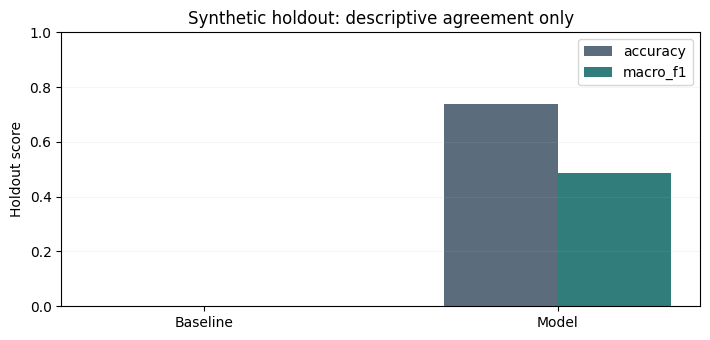

In [12]:
complete=survey.loc[complete_mask].copy()
partial=survey.loc[partial_mask].copy()
X=model_features(complete)
y=complete[TARGET].astype(str)
assigned_groups=groups.loc[complete.index]
train_idx,test_idx=next(GroupShuffleSplit(n_splits=1,test_size=.22,random_state=SEED)
                        .split(X,y,groups=assigned_groups))
assert set(assigned_groups.iloc[train_idx]).isdisjoint(set(assigned_groups.iloc[test_idx]))
X_train,X_test=X.iloc[train_idx],X.iloc[test_idx]
y_train,y_test=y.iloc[train_idx],y.iloc[test_idx]
model=fresh_model().fit(X_train,y_train)
baseline=DummyClassifier(strategy="most_frequent").fit(X_train,y_train)
forecast=model.predict(X_test)
base_forecast=baseline.predict(X_test)
probability_score=model.predict_proba(X_test).max(axis=1)
not_seen=~y_test.isin(set(y_train))

def metric_line(name,pred):
    return {"model":name,"accuracy":accuracy_score(y_test,pred),
            "macro_f1":f1_score(y_test,pred,average="macro",zero_division=0),
            "weighted_f1":f1_score(y_test,pred,average="weighted",zero_division=0)}
performance=pd.DataFrame([metric_line("Dummy baseline",base_forecast),
                          metric_line("TF-IDF + OneHot + LogisticRegression",forecast)])
print("Train:",len(train_idx),"| Test:",len(test_idx),
      "| Unseen-label test records:",int(not_seen.sum()))
display(performance.round(4))
held_out=pd.DataFrame({"ID":complete.iloc[test_idx]["ID"].astype(int).to_numpy(),
                       "manual_code":y_test.to_numpy(),
                       "model_code":forecast,
                       "matches_given_code":forecast==y_test.to_numpy(),
                       "class_seen_in_training":~not_seen.to_numpy(),
                       "uncalibrated_score":np.round(probability_score,3)})
assert held_out.shape[0]==len(test_idx)
print("Complete held-out predictions (all records):")
display(held_out[["ID","manual_code","model_code","matches_given_code"]].reset_index(drop=True))
fig,ax=plt.subplots(figsize=(7.2,3.5))
xs=np.arange(2);width=.32
for j,col in enumerate(["accuracy","macro_f1"]):
    ax.bar(xs+(j-.5)*width,performance[col],width,label=col,
           color=[PALETTE["gray"],PALETTE["teal"]][j])
ax.set_xticks(xs,labels=["Baseline","Model"])
ax.set(ylim=(0,1),ylabel="Holdout score",title="Synthetic holdout: descriptive agreement only")
ax.legend();ax.grid(axis="y",alpha=.12);fig.tight_layout();plt.show()

## 13. ניתוח שגיאות ויציבות על כמה חלוקות בלתי תלויות
המשתנה הנמדד במבחן הוא התאמה לתוויות ידניות עם רעש, לא נכונות לפי תקן מקצועי בלתי תלוי. אין לבחור מודל או סף ע"פ קבוצת הבדיקה. החלוקות הנוספות מוצגות כבדיקת רגישות תיאורית בלבד, לא כהבטחה לדיוק על נתוני אמת.

Holdout disagreements: 11 | of which unseen training label: 8


,ID,manual_code,model_code,class_seen_in_training
3,25,3323,5322,False
15,88,3323,5322,False
25,139,1212,2120,False
26,140,2511,5142,True
27,144,3512,2512,True
32,166,2511,5142,True
33,174,2330,2514,False
35,177,5222,5230,False
36,180,3334,5223,False
38,184,2412,3512,False


,run,n_test,unseen_labels,accuracy,macro_f1
0,1,43,16,0.558,0.252
1,2,36,11,0.556,0.492
2,3,42,9,0.738,0.516
3,4,39,10,0.590,0.388


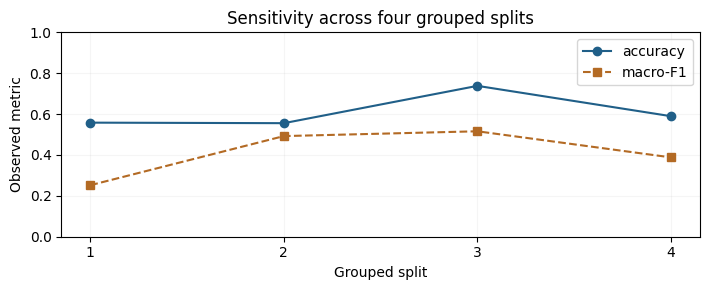

In [13]:
errors=held_out.loc[~held_out["matches_given_code"]]
print("Holdout disagreements:",len(errors),"| of which unseen training label:",
      int((~held_out.matches_given_code & ~held_out.class_seen_in_training).sum()))
display(errors[["ID","manual_code","model_code","class_seen_in_training"]].head(20))

repeated=[]
for run,(tr,te) in enumerate(GroupShuffleSplit(n_splits=4,test_size=.22,random_state=21)
                             .split(X,y,groups=assigned_groups),start=1):
    assert set(assigned_groups.iloc[tr]).isdisjoint(set(assigned_groups.iloc[te]))
    trained=fresh_model().fit(X.iloc[tr],y.iloc[tr])
    pred=trained.predict(X.iloc[te])
    unseen=~y.iloc[te].isin(set(y.iloc[tr]))
    repeated.append({"run":run,"n_test":len(te),"unseen_labels":int(unseen.sum()),
                     "accuracy":accuracy_score(y.iloc[te],pred),
                     "macro_f1":f1_score(y.iloc[te],pred,average="macro",zero_division=0)})
repeated=pd.DataFrame(repeated)
display(repeated.round(3))
fig,ax=plt.subplots(figsize=(7.2,3.0))
ax.plot(repeated.run,repeated.accuracy,"o-",label="accuracy",color=PALETTE["blue"])
ax.plot(repeated.run,repeated.macro_f1,"s--",label="macro-F1",color=PALETTE["orange"])
ax.set(ylim=(0,1),xlabel="Grouped split",ylabel="Observed metric",
       title="Sensitivity across four grouped splits")
ax.set_xticks(repeated.run);ax.legend();ax.grid(alpha=.12)
fig.tight_layout();plt.show()

## 14. הצעות לרשומות חלקיות — החלטה אנושית
לאחר ההערכה, המודל מאומן מחדש על כל 191 הרשומות בעלות קוד מלא ומציע קוד לתשע רשומות עם `X`. ההצעות אינן תחליף לסימולן. תוצאת `predict_proba` אינה הסתברות מכוילת, ואין לקבוע ממנה סף אוטומציה בלי נתוני אמת וערכת כיול עצמאית.

In [14]:
review_model=fresh_model().fit(X,y)
review_features=model_features(partial)
review_proposed=review_model.predict(review_features)
review_score=review_model.predict_proba(review_features).max(axis=1)
review_queue=pd.DataFrame({"ID":partial["ID"].astype(int).to_numpy(),
                           "partial_source_code":partial[TARGET].astype(str).to_numpy(),
                           "suggested_code":review_proposed,
                           "uncalibrated_score":np.round(review_score,3),
                           "decision":"CODER_REVIEW"})
assert len(review_queue)==9
print("All partial-code cases are routed to human review:")
display(review_queue)
print("Model-ready prediction tables: held_out and review_queue")

All partial-code cases are routed to human review:


,ID,partial_source_code,suggested_code,uncalibrated_score,decision
0,18,1XXX,2511,0.093,CODER_REVIEW
1,45,XXXX,2511,0.071,CODER_REVIEW
2,50,1XXX,2511,0.093,CODER_REVIEW
3,81,1XXX,2511,0.093,CODER_REVIEW
4,108,XXXX,2511,0.071,CODER_REVIEW
5,113,1XXX,2511,0.093,CODER_REVIEW
6,142,XXXX,5223,0.096,CODER_REVIEW
7,165,335X,3354,0.266,CODER_REVIEW
8,193,XXXX,5223,0.337,CODER_REVIEW


Model-ready prediction tables: held_out and review_queue


## 15. סיכום הנדסי ותכנית הטמעה
**תוצאה:** תהליך ניתוח, בדיקה ואימון הניתן לשחזור וכולל את 18 השדות. טיפוס הנתונים מפעיל אוטומטית בדיקות, ורק תיעוד המקור מפעיל בדיקות קוד ותחולה תלויות-שדה. חריגות מדווחות ללא תיקון אוטומטי של המקור. החלטות מידול מוצגות בנפרד מההגדרות הרשמיות.

**מגבלות שנותרו פתוחות, שאסור להציגן כפתורות:** אין מזהה משתתף המקשר שידורים חוזרים, אין תאריך שידור, אין אמת-מידה מקצועית מתוקפת, יש מחלקות נדירות ונתוני סקר קטנים. לא ברור אם `SemelAnafSofi` זמין בשלב שבו נדרש חיזוי משלח יד. עם הנתונים הנוכחיים אי אפשר לאמת שיעורי טעות תפעוליים, לבסס סף ביטחון, או להסיק הוגנות של מערכת אוטומטית.

**המשך מומלץ:** (1) מזהה משתתף, מזהה גרסה ותאריך שידור; (2) מדגם תיוג שנבדק על ידי סמלנים בלתי תלויים ומנגנון adjudication; (3) בדיקה לפי משתתף וזמן וניתוח מחלקות לא נראות; (4) כיול סיכונים והימנעות ממתן קוד אוטומטי כשאין ראיות מספיקות; (5) השקה במודל המלצה לסמלן מקצועי וניטור טעויות, זמני טיפול וסטיות נתונים.

**מקורות מתודולוגיים:** [pandas read_excel](https://pandas.pydata.org/docs/reference/api/pandas.read_excel.html) · [pandas to_numeric](https://pandas.pydata.org/docs/reference/api/pandas.to_numeric.html) · [pandas to_datetime](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html) · [scikit-learn Pipeline and leakage](https://scikit-learn.org/stable/common_pitfalls.html) · [scikit-learn GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html) · [scikit-learn ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html).

**עיצוב:** פלטת הצבעים נגזרה מערכי `BLUE`, `TEAL`, `GRAY`, `PALE`, `ORANGE`, `EDGE` בפרויקט `Figures.ipynb` של בעל העבודה. הגרפים כאן הם נתוני הסקר הנמדדים, לא דוגמאות המחשה סינתטיות נוספות.

**אימות ההרצה:** הנתונים נטענו מהעותק המקורי שזוהה באמצעות SHA-256; בדיקת הרצה מקומית אינה שקולה להוכחת ביצוע על שרתי Colab. המחברת משתמשת בספריות הזמינות בסביבת Colab ובקובץ ציבורי שאינו דורש התחברות.